---
title: "Chapter 13: Feature Engineering and Selection"
---

::: {.callout-lo}
By the end of this chapter, you will be able to:

- Distinguish feature engineering, feature selection, and feature importance.
- Explain how interaction features and binning change what a linear model can learn.
- Construct numeric features and evaluate their effect on model performance using cross-validation.
- Use pipelines to fit learned transformations and feature selection within each cross-validation fold.
- Compare model-based selection and recursive feature elimination.
- Choose the number of selected features using cross-validation without leaking validation information.
- Explain why a selected feature set depends on the model, data, and other available features.
:::

## Why change the feature representation?

So far, we have compared models and investigated how they use their inputs. But what if the limitation is how we represent those inputs? Changing the representation can make a useful relationship easier to learn, even without changing the model.

We already do this through scaling, one-hot encoding, and bag-of-words. **Feature engineering** extends that work by constructing inputs using our understanding of the problem. Later, **feature selection** will let us ask whether we need all the available columns. The question throughout this chapter is: what inputs help this model solve this task?

::: {.callout-reflection}
Suppose we predict flight delays before departure. We know the scheduled departure time and expected flight duration. Delays seem more common during evening rush hours. What feature could help a linear model represent that pattern?
:::

An indicator for a scheduled departure during rush hour is one possibility. It lets the model distinguish that period without assuming that each additional hour has the same effect. We would use scheduled rather than actual departure time, which is unavailable when we make the prediction.

Feature engineering makes existing information more accessible to a particular model. We will create interactions and numeric transformations, then investigate when keeping fewer features helps—and when it hurts.

In [1]:
#| code-fold: true
#| code-summary: "Show imports and setup"
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import make_column_transformer
from sklearn.datasets import load_breast_cancer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE, SelectFromModel
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.model_selection import (
    GridSearchCV, KFold, StratifiedKFold, cross_validate, train_test_split,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import KBinsDiscretizer, PolynomialFeatures, StandardScaler

%matplotlib inline
DATA_DIR = Path("data")
plt.rcParams.update({"figure.figsize": (7, 4)})

Matplotlib is building the font cache; this may take a moment.


## Creating interaction features

A linear classifier uses a weighted sum of its features. With two inputs, its decision boundary is a straight line. Consider the following pattern, called **exclusive OR (XOR)**: the target is 1 when the signs of the two inputs differ and 0 when they agree.

| $x_1$ | $x_2$ | Target |
|---|---|---|
| −1 | −1 | 0 |
| 1 | −1 | 1 |
| −1 | 1 | 1 |
| 1 | 1 | 0 |

No straight line separates these two classes in the original plane. But their product, $x_1x_2$, is negative exactly when the signs differ. Adding that product gives the model a useful new input. We call it an **interaction feature**, or feature cross: it represents a combination of inputs.

In [2]:
xor_table = pd.DataFrame({
    "x1": [-1, 1, -1, 1],
    "x2": [-1, -1, 1, 1],
    "target": [0, 1, 1, 0],
})
xor_table["x1_x2"] = xor_table["x1"] * xor_table["x2"]
xor_table

,x1,x2,target,x1_x2
0,-1,-1,0,1
1,1,-1,1,-1
2,-1,1,1,-1
3,1,1,0,1


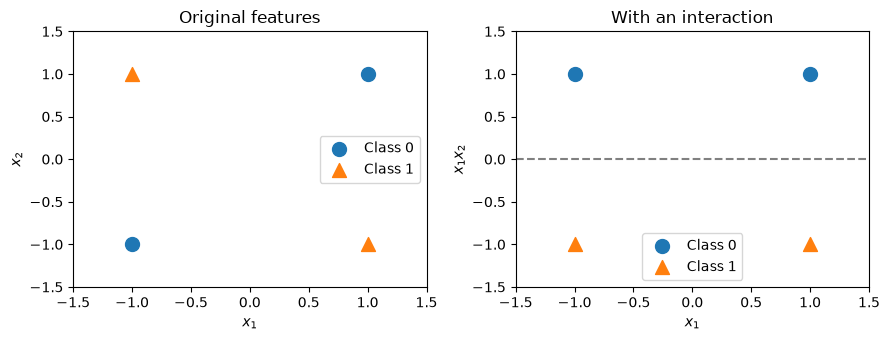

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for label, marker in [(0, "o"), (1, "^")]:
    rows = xor_table[xor_table["target"] == label]
    axes[0].scatter(rows["x1"], rows["x2"], marker=marker, s=100, label=f"Class {label}")
    axes[1].scatter(rows["x1"], rows["x1_x2"], marker=marker, s=100, label=f"Class {label}")
axes[0].set(xlabel="$x_1$", ylabel="$x_2$", title="Original features")
axes[1].set(xlabel="$x_1$", ylabel="$x_1 x_2$", title="With an interaction")
axes[1].axhline(0, color="grey", linestyle="--")
for ax in axes:
    ax.set(xlim=(-1.5, 1.5), ylim=(-1.5, 1.5))
    ax.legend()
plt.tight_layout()
plt.show()

The dashed line separates the classes in the transformed space. The model remains linear in its supplied features, but its boundary need not be linear in the original inputs. This is a useful distinction: a linear model does not require us to supply only the raw measurements.

### Generating interactions in a pipeline

Let's use a larger sample with the same rule. We compare logistic regression with and without the product feature on identical cross-validation folds.

In [4]:
rng = np.random.default_rng(0)
X_xor = pd.DataFrame(rng.normal(size=(400, 2)), columns=["x1", "x2"])
y_xor = (X_xor["x1"] > 0) != (X_xor["x2"] > 0)
xor_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)

xor_models = {
    "Original features": make_pipeline(StandardScaler(), LogisticRegression()),
    "With interaction": make_pipeline(
        PolynomialFeatures(degree=2, interaction_only=True, include_bias=False),
        StandardScaler(),
        LogisticRegression(),
    ),
}
xor_results = {}
for name, model in xor_models.items():
    scores = cross_validate(model, X_xor, y_xor, cv=xor_cv, scoring="accuracy")
    xor_results[name] = {
        "Mean validation accuracy": scores["test_score"].mean(),
        "Fold standard deviation": scores["test_score"].std(),
    }
pd.DataFrame(xor_results).T.round(3)

,Mean validation accuracy,Fold standard deviation
Original features,0.515,0.046
With interaction,0.972,0.027


Here, the interaction substantially improves validation accuracy. `PolynomialFeatures` with `degree=2` and `interaction_only=True` retains the original inputs and adds pairwise products, omitting squares such as $x_1^2$. We set `include_bias=False` because logistic regression already fits an intercept. Scaling follows feature creation so the generated feature is scaled too.

Inspecting the transformed names makes the extra column explicit.

In [5]:
xor_models["With interaction"].fit(X_xor, y_xor)
xor_models["With interaction"].named_steps["polynomialfeatures"].get_feature_names_out()

array(['x1', 'x2', 'x1 x2'], dtype=object)

An interaction does not introduce new measurements: its value is determined by the original inputs. It changes which relationships the model can express easily. A tree can already represent this XOR rule through successive splits, so the same transformation need not help every model.

### Interactions between categories

Suppose we predict parking availability from location (UBC campus or Rogers Arena) and time (9 a.m. or 7 p.m.). An additive linear model gives each time the same effect at both locations. But evenings may be quiet on campus and busy near an arena during an event.

Multiplying one-hot indicators creates a feature that is 1 only when both conditions hold, such as “Rogers Arena **and** 7 p.m.” An interaction lets that combination have an additional effect. Another option is to construct a combined category and one-hot encode it. Either way, retain enough observations of each combination to learn something useful.

Generating every possible cross can quickly create many columns, including combinations that never occur. Start with interactions motivated by the task, compare them using validation data, and consider whether a model that already captures interactions would be a better fit.

### iClicker 13.1: What did the new feature add?

Logistic regression performs much better on XOR after we add $x_1x_2$. Which explanation is most accurate? **Choose one.**

- (A) We collected a new measurement that was missing from the data.
- (B) The product makes the pattern representable by a linear classifier in the transformed space.
- (C) Adding any feature must improve validation accuracy.
- (D) The product will improve every model, including trees, by the same amount.

::: {.callout-tip collapse="true" title="Answer and explanation"}
**B.** The product is calculated from existing inputs, so it adds no new measurements. It changes what a linear classifier can express. Extra features can also fit noise, and trees can already capture interactions through successive splits. The benefit depends on the model and data.
:::

## Engineering numeric features

We now return to the California housing data. Each row describes a census block group, rather than an individual property; the target is its median house value. We will use a deliberately small set of inputs to make changes in representation easy to inspect. This is not an attempt to build the strongest housing model.

The file belongs in `data/california_housing.csv`, relative to this notebook. We reserve a test set before exploring the training data. A random split is useful for this illustration; predicting in entirely new geographic areas would require a validation design that holds out areas.

In [6]:
housing = pd.read_csv(DATA_DIR / "california_housing.csv")
housing_train, housing_test = train_test_split(housing, test_size=0.2, random_state=123)
housing_train[["longitude", "latitude", "total_rooms", "households", "median_house_value"]].head()

,longitude,latitude,total_rooms,households,median_house_value
9950,-122.33,38.38,1020.0,164.0,287500.0
3547,-118.60,34.26,6154.0,1034.0,271500.0
4448,-118.21,34.07,1346.0,371.0,191700.0
6984,-118.02,33.96,2071.0,404.0,219700.0
4432,-118.20,34.08,1320.0,328.0,114000.0


### Ratios: describing a typical household

A block group with many rooms may simply have many households. Dividing total rooms by households gives a rough measure of rooms per household. It answers a different question from the total count.

This is a fixed calculation on each row: it learns no averages or other quantities from the dataset. We can apply the same rule to training and test rows. If a denominator is zero, we treat the ratio as missing rather than creating infinity; the pipeline will learn how to impute it using its training fold.

In [7]:
def add_rooms_per_household(frame):
    return frame.assign(
        rooms_per_household=frame["total_rooms"] / frame["households"].replace(0, np.nan)
    )

housing_train = add_rooms_per_household(housing_train)
housing_test = add_rooms_per_household(housing_test)
housing_features = ["latitude", "longitude", "rooms_per_household"]
X_housing = housing_train[housing_features]
y_housing = housing_train["median_house_value"]
housing_cv = KFold(n_splits=5, shuffle=True, random_state=123)

A deployment would need this same calculation on every new row. For a larger workflow, we could package it as a pipeline transformation. Here, keeping the small function visible helps distinguish a fixed row calculation from learned transformations such as imputation and scaling.

To check whether the ratio is useful, compare it with the two counts from which it was made. Both candidates also include latitude and longitude.

In [8]:
count_features = ["latitude", "longitude", "total_rooms", "households"]
count_model = make_pipeline(
    make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), count_features)
    ),
    Ridge(alpha=1.0),
)
ratio_model = make_pipeline(
    SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=1.0)
)

housing_results = {}
def evaluate_housing(name, model, X):
    scores = cross_validate(
        model, X, y_housing, cv=housing_cv, scoring="r2", return_train_score=True
    )
    housing_results[name] = {
        "Mean training R²": scores["train_score"].mean(),
        "Mean validation R²": scores["test_score"].mean(),
        "Validation standard deviation": scores["test_score"].std(),
    }

evaluate_housing("Raw counts", count_model, housing_train[count_features])
evaluate_housing("Ratio, continuous inputs", ratio_model, X_housing)
pd.DataFrame(housing_results).T.round(3)

,Mean training R²,Mean validation R²,Validation standard deviation
Raw counts,0.313,0.312,0.004
"Ratio, continuous inputs",0.306,0.301,0.019


The ratio is a plausible feature, but here replacing the counts lowers mean validation $R^2$ slightly, from about 0.312 to 0.301. Plausibility alone does not establish an improvement. Replacing the counts also discards their separate values; another candidate could retain both the counts and the ratio. Next, we hold these three inputs fixed and investigate how a linear model represents their effects. This separates the choice of quantity from the choice of representation.

### Binning: allowing different effects in different ranges

With continuous latitude and longitude, ridge regression assigns a constant change in prediction to each additional degree, holding the other inputs fixed. That is restrictive: moving north does not have to change housing prices at the same rate throughout California.

**Binning**, also called discretization, divides a numeric feature into intervals. One-hot encoding those intervals gives a linear model a separate coefficient for each interval. Its contribution is constant within a bin and can jump at the boundary.

`KBinsDiscretizer` learns the boundaries during fitting. We use 20 quantile bins, which aim for similar numbers of training observations per bin; ties can prevent an exact balance. Because the boundaries depend on data, the discretizer belongs inside the cross-validated pipeline. See the [scikit-learn binning example](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_discretization.html) for a visual comparison with continuous inputs.

In [9]:
def make_bins():
    return KBinsDiscretizer(
        n_bins=20, encode="onehot-dense", strategy="quantile",
        quantile_method="averaged_inverted_cdf", subsample=None,
    )

location_preprocessor = make_column_transformer(
    (make_bins(), ["latitude", "longitude"]),
    (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), ["rooms_per_household"]),
)
location_model = make_pipeline(location_preprocessor, Ridge(alpha=1.0))
all_binned_model = make_pipeline(
    SimpleImputer(strategy="median"), make_bins(), Ridge(alpha=1.0)
)

evaluate_housing("Binned location", location_model, X_housing)
evaluate_housing("All three inputs binned", all_binned_model, X_housing)
pd.DataFrame(housing_results).T.round(3)

,Mean training R²,Mean validation R²,Validation standard deviation
Raw counts,0.313,0.312,0.004
"Ratio, continuous inputs",0.306,0.301,0.019
Binned location,0.456,0.448,0.021
All three inputs binned,0.577,0.572,0.010


Compare each change with the preceding representation. Binning improves validation scores in this example, but it also changes the model's flexibility. We have held ridge's `alpha` fixed to isolate the workflow; a more complete comparison would tune regularization for each representation. The fold standard deviations show how much the validation scores vary across the cross-validation folds.

We use dense one-hot output because this example has only about 60 transformed columns. For many features or bins, sparse output can save memory. The location columns in this file have no missing values; the ratio branch includes imputation for missing ratios.

Let's inspect the learned room-ratio boundaries and the contribution of each bin. We fit on the training data for inspection, leaving the test set aside.

In [10]:
all_binned_model.fit(X_housing, y_housing)
binner = all_binned_model.named_steps["kbinsdiscretizer"]
transformed_names = binner.get_feature_names_out(housing_features)
room_edges = binner.bin_edges_[2]
room_start = int(binner.n_bins_[:2].sum())
room_coefficients = all_binned_model.named_steps["ridge"].coef_[room_start:]
room_bins = pd.DataFrame({
    "Lower boundary": room_edges[:-1],
    "Upper boundary": room_edges[1:],
    "Coefficient": room_coefficients,
})
room_bins.head()

,Lower boundary,Upper boundary,Coefficient
0,0.846154,3.430645,-50826.779079
1,3.430645,3.783954,-51103.894396
2,3.783954,4.040000,-47669.848233
3,4.040000,4.254021,-41998.907527
4,4.254021,4.430466,-40770.918428


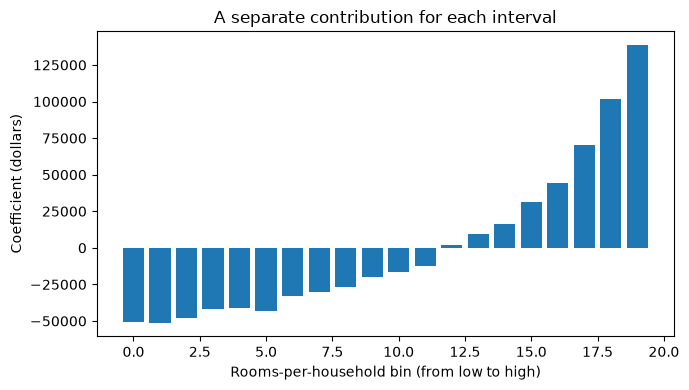

In [11]:
fig, ax = plt.subplots()
ax.bar(np.arange(len(room_coefficients)), room_coefficients)
ax.set(
    xlabel="Rooms-per-household bin (from low to high)",
    ylabel="Coefficient (dollars)",
    title="A separate contribution for each interval",
)
plt.tight_layout()
plt.show()

These coefficients need not rise at a constant rate. As in Chapter 12, differences between one-hot coefficients describe changes between categories, holding other inputs fixed. They describe the fitted model, not the causal effect of adding rooms. New values beyond the fitted range go into an end bin, so this representation does not extrapolate a trend beyond that range.

Binning also loses distinctions within each interval and creates abrupt changes at boundaries. More bins allow finer changes but leave fewer observations to estimate each contribution. The bin count is a hyperparameter to choose through validation.

Separately binning latitude and longitude still gives an additive model: each latitude band's contribution is shared across all longitudes. Crossing the two sets of indicators would allow different contributions for geographic cells, but many cells could have little or no data.

### iClicker 13.2: Predict what binning changes

Two otherwise identical observations have rooms-per-household values of 4.01 and 4.09 in the same bin. A third has a value of 4.10, just across a bin boundary. How does the binned ridge model treat these values? **Choose one.**

- (A) Each increase of 0.01 must have the same effect on the prediction.
- (B) All three must have the same contribution because their values are close.
- (C) The first two have the same contribution; the third can have a different contribution.
- (D) The third must have a higher prediction because it has a larger value.

::: {.callout-tip collapse="true" title="Answer and explanation"}
**C.** Values within a bin share an indicator and its coefficient. Crossing a boundary can change the contribution abruptly, in either direction. More bins allow finer changes but leave fewer observations per bin, so they do not necessarily improve validation performance.
:::

## Why remove features?

Interactions and bins can create many columns; datasets can also arrive with many measurements already recorded. Some inputs may duplicate information or offer opportunities to fit accidental patterns. **Feature selection** keeps a subset of columns and refits the predictor using them.

A smaller model may be easier to inspect and cheaper to use. Removing an expensive measurement can reduce collection cost, although dropping a few one-hot columns may still require collecting their original variable. Fewer columns also do not guarantee an understandable model: their meaning matters.

Can selection improve prediction too? We will first construct a case with irrelevant inputs, then examine a dataset where removing features hurts. In both cases, the comparison is with an all-features baseline. Regularization remains another way to control flexibility without explicitly removing columns.

## Selecting features with models

Chapter 12 introduced coefficients and tree feature importances. These can propose a subset, but the practical question is how well a predictor performs after being refitted on that subset.

### Model-based selection

The procedure has two model roles. First, fit a **selection model** to obtain feature importances and keep columns that reach a threshold. Then fit the **final predictor** using those columns. The selection model chooses inputs; its predictions are not passed to the final predictor.

[`SelectFromModel`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SelectFromModel.html) implements the selection as a transformer. During `fit`, it learns which columns to keep; during `transform`, it keeps those same columns. Our pipeline is:

**Scale inputs $\to$ forest selects columns $\to$ logistic regression predicts.**

Scaling serves logistic regression; the forest does not require it. Keeping the selector inside the pipeline ensures that each validation fold learns its selection using only that fold's training data.

### When irrelevant inputs get in the way

We generate 300 observations with 100 independent numeric features. Only the first three determine the target, with additional random noise. The remaining 97 are unrelated to the target, although some will appear associated by chance in a finite sample. In real data, we would not know which features generated the outcome.

Compare logistic regression on the three relevant inputs, on all 100 inputs, and after forest-based selection. We use the mean forest importance as the threshold, fixed for this demonstration, and identical validation folds.

In [12]:
rng = np.random.default_rng(42)
X_noise = pd.DataFrame(rng.normal(size=(300, 100)), columns=[f"x{i}" for i in range(100)])
y_noise = (3 * X_noise["x0"] - 3 * X_noise["x1"] + 2 * X_noise["x2"]
           + rng.normal(size=300)) > 0
noise_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
noise_selector = make_pipeline(
    StandardScaler(),
    SelectFromModel(RandomForestClassifier(n_estimators=100, random_state=42), threshold="mean"),
    LogisticRegression(max_iter=2000),
)
noise_results = {}
for name, model, inputs in [
    ("Known relevant inputs", make_pipeline(StandardScaler(), LogisticRegression()), X_noise.iloc[:, :3]),
    ("All inputs", make_pipeline(StandardScaler(), LogisticRegression()), X_noise),
    ("Forest-selected inputs", noise_selector, X_noise),
]:
    scores = cross_validate(model, inputs, y_noise, cv=noise_cv, return_estimator=True)
    counts = ([m.named_steps["selectfrommodel"].get_support().sum() for m in scores["estimator"]]
              if name == "Forest-selected inputs" else [inputs.shape[1]])
    noise_results[name] = {
        "Mean validation accuracy": scores["test_score"].mean(),
        "Fold standard deviation": scores["test_score"].std(),
        "Mean features retained": np.mean(counts),
    }
pd.DataFrame(noise_results).T.round(3)

,Mean validation accuracy,Fold standard deviation,Mean features retained
Known relevant inputs,0.920,0.034,3.0
All inputs,0.803,0.051,100.0
Forest-selected inputs,0.907,0.065,15.6


Adding unrelated inputs lowers mean validation accuracy here, and selection recovers much of the loss using fewer columns. The known-relevant-inputs result is a reference available only because we constructed the data. Selection does not necessarily recover exactly those three features, and different folds can retain different counts.

This is a controlled illustration, not a guarantee. The benefit depends on the sample size, irrelevant inputs, model, and regularization. A smaller set gives us fewer contributions to inspect; whether we can explain them still depends on what the features mean.

### When keeping all features works better

Now use the breast-cancer dataset: 30 numeric measurements derived from images of cell nuclei, with malignant and benign labels. This compact dataset lets us study selection without additional preprocessing machinery. We establish the all-features baseline before selecting anything.

In [13]:
cancer = load_breast_cancer(as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(
    cancer.data, cancer.target, test_size=0.5, random_state=0, stratify=cancer.target
)
selection_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
all_features_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
selection_results = {}

def evaluate_selection(name, model):
    scores = cross_validate(
        model, X_train, y_train, cv=selection_cv, scoring="accuracy", return_train_score=True, return_estimator=True
    )
    selection_results[name] = {
        "Mean features retained": np.mean([
            m[:-1].transform(X_train).shape[1] if hasattr(m, "steps") else X_train.shape[1]
            for m in scores["estimator"]
        ]),
        "Mean training accuracy": scores["train_score"].mean(),
        "Mean validation accuracy": scores["test_score"].mean(),
        "Validation standard deviation": scores["test_score"].std(),
    }

evaluate_selection("Dummy baseline", DummyClassifier(strategy="most_frequent"))
evaluate_selection("All 30 features", all_features_model)
pd.DataFrame(selection_results).T.round(3)

,Mean features retained,Mean training accuracy,Mean validation accuracy,Validation standard deviation
Dummy baseline,30.0,0.627,0.627,0.007
All 30 features,30.0,0.989,0.979,0.013


In [14]:
model_based = make_pipeline(
    StandardScaler(),
    SelectFromModel(
        RandomForestClassifier(n_estimators=100, random_state=42), threshold="median"
    ),
    LogisticRegression(max_iter=2000),
)
evaluate_selection("Forest-based selection", model_based)
pd.DataFrame(selection_results).T.round(3)

,Mean features retained,Mean training accuracy,Mean validation accuracy,Validation standard deviation
Dummy baseline,30.0,0.627,0.627,0.007
All 30 features,30.0,0.989,0.979,0.013
Forest-based selection,15.0,0.974,0.961,0.036


Here we use `threshold="median"`, retaining roughly half the columns; ties can retain more. The forest's preferred inputs need not be the best subset for logistic regression. Its importances also inherit the limitations discussed in Chapter 12.

After evaluation, fit on the training split to inspect the threshold and selected columns. This is one fitted selection; cross-validation fitted a separate selector in each fold.

In [15]:
model_based.fit(X_train, y_train)
selector = model_based.named_steps["selectfrommodel"]
pd.DataFrame({
    "Feature": X_train.columns,
    "Forest importance": selector.estimator_.feature_importances_,
    "Retained": selector.get_support(),
}).sort_values("Forest importance", ascending=False).assign(Threshold=selector.threshold_)

,Feature,Forest importance,Retained,Threshold
23,worst area,0.134191,True,0.011402
27,worst concave points,0.116113,True,0.011402
20,worst radius,0.106872,True,0.011402
22,worst perimeter,0.096692,True,0.011402
2,mean perimeter,0.081823,True,0.011402
7,mean concave points,0.077008,True,0.011402
0,mean radius,0.074356,True,0.011402
6,mean concavity,0.073012,True,0.011402
3,mean area,0.040202,True,0.011402
13,area error,0.034153,True,0.011402


By default, the selection estimator needs `coef_` or `feature_importances_`. KNN and an RBF-kernel SVC do not supply these; a linear SVC does. For coefficients, magnitude matters: a large negative coefficient can be important.

### Recursive feature elimination

Selecting once uses importances calculated with all features present. But two related measurements might substitute for one another: after removing one, the other may become more important. What if we refit after each removal?

**Recursive feature elimination (RFE)** does this. Fit a model, remove its least important remaining feature, refit, and repeat until the desired count remains. Removing several features per step is faster but follows a coarser elimination path.

Below, logistic regression inside RFE guides elimination; the final logistic regression fits the retained inputs. Scaling makes coefficient magnitudes comparable. We start with five features as an illustrative choice.

In [16]:
rfe_model = make_pipeline(
    StandardScaler(),
    RFE(LogisticRegression(max_iter=2000), n_features_to_select=5, step=1),
    LogisticRegression(max_iter=2000),
)
evaluate_selection("RFE: 5 features", rfe_model)
pd.DataFrame(selection_results).T.round(3)

,Mean features retained,Mean training accuracy,Mean validation accuracy,Validation standard deviation
Dummy baseline,30.0,0.627,0.627,0.007
All 30 features,30.0,0.989,0.979,0.013
Forest-based selection,15.0,0.974,0.961,0.036
RFE: 5 features,5.0,0.962,0.947,0.025


In [17]:
rfe_model.fit(X_train, y_train)
rfe = rfe_model.named_steps["rfe"]
rfe_ranking = pd.DataFrame({
    "Feature": X_train.columns,
    "Selected": rfe.support_,
    "RFE rank": rfe.ranking_,
})
rfe_ranking.sort_values("RFE rank").head(10)

,Feature,Selected,RFE rank
22,worst perimeter,True,1
7,mean concave points,True,1
23,worst area,True,1
20,worst radius,True,1
27,worst concave points,True,1
21,worst texture,False,2
6,mean concavity,False,3
10,radius error,False,4
13,area error,False,5
26,worst concavity,False,6


All retained features have rank 1. The other ranks describe the elimination process; they are not the original model's importance order, and they do not measure how much worse one feature is than another.

Here, mean validation accuracy falls from about 0.979 with all features to 0.961 with forest-based selection and 0.947 with five-feature RFE. Removing features has not improved predictive performance in this comparison. Unlike the noise example, these smaller feature sets perform worse in validation. A smaller subset might still be worthwhile if it reduces a real cost, but it is not an accuracy improvement.

### Choosing how many features to keep

Five was an illustrative choice. We can treat the number of selected features as a hyperparameter, using the search workflow from Chapter 8. Searching the **whole pipeline** ensures that scaling and selection are refitted inside each search fold.

In [18]:
selection_search = GridSearchCV(
    clone(rfe_model),
    param_grid={"rfe__n_features_to_select": [5, 10, 15, 20, 30]},
    cv=selection_cv,
    scoring="accuracy",
)
selection_search.fit(X_train, y_train)
search_results = pd.DataFrame(selection_search.cv_results_)
search_results[[
    "param_rfe__n_features_to_select", "mean_test_score", "std_test_score", "rank_test_score"
]].sort_values("rank_test_score")

,param_rfe__n_features_to_select,mean_test_score,std_test_score,rank_test_score
4,30,0.978822,0.013264,1
1,10,0.971742,0.014365,2
2,15,0.971742,0.014365,2
3,20,0.971742,0.014365,2
0,5,0.947055,0.025258,5


Including 30 features gives the search an option that removes nothing. The best cross-validation score helped us choose the feature count, so it is not an independent evaluation of that choice. Once the candidate set and selection rule are fixed, evaluate the selected pipeline once on the held-out test data.

In [19]:
pd.Series({
    "Chosen number of features": selection_search.best_params_["rfe__n_features_to_select"],
    "Best mean CV accuracy": selection_search.best_score_,
    "Final test accuracy": selection_search.score(X_test, y_test),
})

Chosen number of features    30.000000
Best mean CV accuracy         0.978822
Final test accuracy           0.978947
dtype: float64

The search selects all 30 features, and final test accuracy is about 0.979. Keeping every feature is a legitimate outcome: there is no requirement that a feature-selection experiment end by removing something. Use this test result to report the completed workflow, not to choose a different feature count. If we wanted to estimate the entire search procedure through cross-validation instead, we would need outer folds that hold out data from the inner search.

::: {.callout-note collapse="true" title="Optional: RFECV and sequential selection"}
[`RFECV`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.RFECV.html) combines recursive elimination with cross-validation to choose the number of features. Its internal folds need the same care as any other validation split. In particular, placing a scaler before `RFECV` fits that scaler before RFECV creates its internal folds. The whole-pipeline grid search above makes the fitting boundary explicit and also lets us evaluate only a short list of feature counts.

Forward selection starts with no features and adds the candidate that gives the best validation score at each step. Backward selection starts with all features and compares candidate removals. Unlike RFE's importance-based removal, these methods compare predictive scores for candidate subsets. They can be expensive and do not guarantee the globally best subset. They are useful alternatives when the estimator does not supply feature importances.
:::

## Making and evaluating feature decisions

The two selection examples give different answers: removing inputs can improve generalization or discard useful information. Judge the trade-off using validation performance, ease of inspection, and actual measurement costs. Correlated features can substitute for one another, and weak individual features can matter together, as XOR illustrates. A selected set is neither a unique list of relevant features nor evidence of causality.

Keep the distinction between **fixed rules** and **learned decisions** clear. Calculating rooms per household uses only values in one row. Fitting bin boundaries, imputing medians, and selecting columns from targets learn from a dataset. Those operations must be fitted within each training fold. Even a fixed formula can overfit the development process if we try many formulas and keep whichever happens to score best.

### iClicker 13.3: Find the leakage

A student fits `SelectFromModel` on all the available labelled data, transforms the inputs, and then cross-validates logistic regression on the reduced matrix. Is this evaluation valid? **Choose one.**

- (A) Yes, because logistic regression never sees validation targets during fitting.
- (B) Yes, because feature selection is a transformation rather than the final predictor.
- (C) No, because cross-validation requires every fold to use the same selected features.
- (D) No, because validation targets helped choose the columns before cross-validation began.

::: {.callout-tip collapse="true" title="Answer and explanation"}
**D.** The selector learns from targets too. Reserve the test set first, then cross-validate a pipeline containing preprocessing, selection, and the classifier on the training split. Different folds may legitimately select different features because of sampling variation and interchangeable correlated inputs.
:::

For discussion: selection improved accuracy in the noise example but reduced it in the breast-cancer example. What would you compare before deciding to use selection on a new dataset?

The scikit-learn guide to [data leakage during feature selection](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage-during-pre-processing) includes an example where selection before splitting creates misleading performance even with random labels.

| Situation | Useful starting choice | What to check |
|---|---|---|
| An effect depends on a combination of inputs | Add a motivated interaction | Are combinations well represented, and does validation improve? |
| A linear effect is too restrictive | Try bins or another transformation | Lost detail, abrupt boundaries, and model complexity |
| There are many potentially redundant inputs | Compare selection with an all-features baseline | Predictive performance, selection stability, and actual measurement costs |
| The current model works well with all inputs | Keep it as a serious candidate | Selection adds fitting cost and can remove useful information |
| An importance plot suggests dropping a feature | Refit and evaluate the proposed subset | Importance for one fitted model does not establish performance after removal |

## Chapter summary

- **Feature engineering changes the representation available to a model.** Ratios express quantities that raw counts can obscure, interactions represent combinations of inputs, and bins allow different contributions over different ranges.
- These choices change what a model can learn and may discard information. Evaluate their effect rather than assuming they help.
- **Feature selection keeps a subset of columns.** Model-based selection uses an importance threshold; RFE refits and removes features repeatedly.
- More features do not guarantee better predictions, and removing features can help or hurt. Compare selection with an all-features baseline.
- Fit learned transformations and selection within each training fold, and choose selection settings using cross-validation. Reserve the test set for the final evaluation.
- Judge feature decisions by predictive performance, ease of inspection, and actual measurement costs. A selected subset is not a permanent ranking of which features matter.
